Dataset description: The dataset contains data from P&G's marketing channels related to revenue and various factors that may impact it. The columns (independent variables) are: the number of "tweets" (including WeChat posts), local TV ad spend, online ad spend, instore investment (marketing materials), number of employees working involved, and whether there was a promotional event (and if so, what type). The dependent variable is revenue. The rows are data from store locations.


In [365]:
#data prep/cleaning
#import necessary tools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import dataset
data = pd.read_csv('P&G Marketing Data.csv')

In [366]:
#check for missing data
data.isnull().any()
data.isnull().sum()
#56 rows are missing data for TV ad spend, which is significant
#delete rows with missing data
data = data.dropna(axis=0)
data.isnull().any()
#rows with missing data have been dropped


Unnamed: 0    False
revenue       False
reach         False
local_tv      False
online        False
instore       False
person        False
event         False
dtype: bool

In [367]:
#check types of data in the dataframe
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 929 entries, 0 to 984
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  929 non-null    int64  
 1   revenue     929 non-null    float64
 2   reach       929 non-null    int64  
 3   local_tv    929 non-null    float64
 4   online      929 non-null    int64  
 5   instore     929 non-null    int64  
 6   person      929 non-null    int64  
 7   event       929 non-null    object 
dtypes: float64(2), int64(5), object(1)
memory usage: 65.3+ KB


In [368]:
#identify event categories
categories = data['event'].unique()
categories

array(['non_event', 'special', 'cobranding', 'holiday'], dtype=object)

In [369]:
# there are objects in the event column; these will have to be changed into numerical values

def event2num(event_string):
    if event_string == 'non-event':
        return 0
    elif event_string == 'special':
        return 1
    elif event_string == 'cobranding':
        return 2
    else:
        return 3
data['event_num'] = data['event'].apply(event2num)
data.head()

,Unnamed: 0,revenue,reach,local_tv,online,instore,person,event,event_num
0,845,45860.28,2,31694.91,2115,3296,8,non_event,3
1,483,63588.23,2,35040.17,1826,2501,14,special,1
2,513,23272.69,4,30992.82,1851,2524,6,special,1
3,599,45911.23,2,29417.78,2437,3049,12,special,1
4,120,36644.23,2,35611.11,1122,1142,13,cobranding,2


In [370]:
#delete event column
data.drop(['event'], axis=1, inplace=True)
data.head()

,Unnamed: 0,revenue,reach,local_tv,online,instore,person,event_num
0,845,45860.28,2,31694.91,2115,3296,8,3
1,483,63588.23,2,35040.17,1826,2501,14,1
2,513,23272.69,4,30992.82,1851,2524,6,1
3,599,45911.23,2,29417.78,2437,3049,12,1
4,120,36644.23,2,35611.11,1122,1142,13,2


In [371]:
#change event_num to event
data.rename(columns={'event_num':'event'}, inplace=True)
data.head()

,Unnamed: 0,revenue,reach,local_tv,online,instore,person,event
0,845,45860.28,2,31694.91,2115,3296,8,3
1,483,63588.23,2,35040.17,1826,2501,14,1
2,513,23272.69,4,30992.82,1851,2524,6,1
3,599,45911.23,2,29417.78,2437,3049,12,1
4,120,36644.23,2,35611.11,1122,1142,13,2


In [372]:
#check/change column names to improve clarity
data.columns = ['Store_Num', 'Revenue', 'X/WeChat_Posts', 'Local_TV_Spend', 'Digital_Spend', 'Instore_Spend', 'Employees_Involved', 'Event_Type']
data.head()

,Store_Num,Revenue,X/WeChat_Posts,Local_TV_Spend,Digital_Spend,Instore_Spend,Employees_Involved,Event_Type
0,845,45860.28,2,31694.91,2115,3296,8,3
1,483,63588.23,2,35040.17,1826,2501,14,1
2,513,23272.69,4,30992.82,1851,2524,6,1
3,599,45911.23,2,29417.78,2437,3049,12,1
4,120,36644.23,2,35611.11,1122,1142,13,2


In [ ]:
#import linear regression 
from sklearn.linear_model import LinearRegression
model = LinearRegression()
#set independent variables as X
#exclude Store_Num from model
X = data.iloc[:, [2,3,4,5,6,7]]
X.head()
#set dependent variable (Revenue) as y
y = data.iloc[:, 1]
y.head()
#import train test split
from sklearn.model_selection import train_test_split
#set training to 70% and testing to 30%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
#fit the model
model.fit(X_train, y_train)


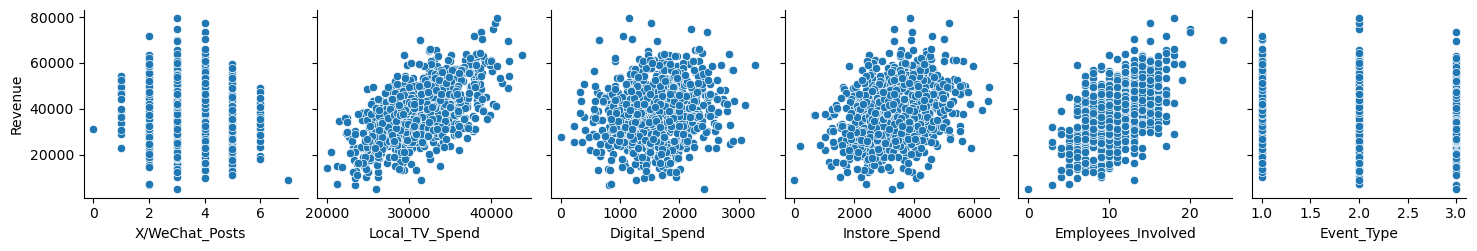

In [374]:
#no need to drop columns (ie: data.drop['Employees'], axis=1, inplace=True) for now. After running the regression, I may need to drop one or more to reduce collinearity
#use seaborn to get an idea of the linear regression model
import seaborn as sns
%matplotlib inline
sns.pairplot(data, x_vars=['X/WeChat_Posts', 'Local_TV_Spend', 'Digital_Spend', 'Instore_Spend', 'Employees_Involved', 'Event_Type'], y_vars='Revenue')
plt.show()

In [375]:
#coefficients
model.coef_

array([-2.13804922e+03,  1.76905758e+00,  3.29649775e+00,  4.00266074e+00,
        2.09380300e+03, -2.20082019e+02])

In [376]:
#intercept
model.intercept_

-51385.57000749237

In [377]:
model.predict(X_test)

array([29868.06472861, 31154.50595656, 28681.72983795, 36417.23529634,
       28557.49588551, 56904.84109425,  4266.74062263, 21780.93456639,
       50917.82685342, 40324.01551803, 36428.68275154, 35774.39547148,
       41113.67240026, 57790.76437801, 39079.18064855, 41536.01741677,
       45674.93048782, 36397.44270126, 55536.96411561, 41466.0110324 ,
       50938.13414439, 49345.24000022, 50313.13759634, 46109.62631397,
       52730.8838504 , 43466.49152894, 43659.85681785, 42711.3388319 ,
       48975.7337914 , 47631.70824554, 47466.63815101, 17967.60672564,
       29050.97295126, 52531.8061342 , 35289.42749129, 46563.00531944,
       30955.35400088, 43260.84918422, 31508.1397974 , 65132.09573471,
       33211.6287447 , 31726.02884116, 46596.84584047, 44433.72719714,
       32334.18898868, 53720.94901945, 35353.82424043, 29267.01856618,
       38293.31699723, 35933.3938714 , 35854.07037924, 27747.81995514,
       26785.78429522, 46501.70692301, 32648.23775236, 33078.63170882,
      

In [378]:
y_pred = model.predict(X_test)
y_pred

array([29868.06472861, 31154.50595656, 28681.72983795, 36417.23529634,
       28557.49588551, 56904.84109425,  4266.74062263, 21780.93456639,
       50917.82685342, 40324.01551803, 36428.68275154, 35774.39547148,
       41113.67240026, 57790.76437801, 39079.18064855, 41536.01741677,
       45674.93048782, 36397.44270126, 55536.96411561, 41466.0110324 ,
       50938.13414439, 49345.24000022, 50313.13759634, 46109.62631397,
       52730.8838504 , 43466.49152894, 43659.85681785, 42711.3388319 ,
       48975.7337914 , 47631.70824554, 47466.63815101, 17967.60672564,
       29050.97295126, 52531.8061342 , 35289.42749129, 46563.00531944,
       30955.35400088, 43260.84918422, 31508.1397974 , 65132.09573471,
       33211.6287447 , 31726.02884116, 46596.84584047, 44433.72719714,
       32334.18898868, 53720.94901945, 35353.82424043, 29267.01856618,
       38293.31699723, 35933.3938714 , 35854.07037924, 27747.81995514,
       26785.78429522, 46501.70692301, 32648.23775236, 33078.63170882,
      

In [379]:
#import metrics to test accuracy
from sklearn import metrics
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y_test, y_pred))

root of mean squared error:  5158.249804068789
mean absolute error:  26607541.041175697


In [380]:
import statsmodels.api as sm
X_intercept = sm.add_constant(X_train)
m = sm.OLS(y_train, X_intercept).fit()
m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Revenue   R-squared:                       0.820
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     488.1
Date:                Sun, 02 Mar 2025   Prob (F-statistic):          1.41e-235
Time:                        21:08:30   Log-Likelihood:                -6458.4
No. Observations:                 650   AIC:                         1.293e+04
Df Residuals:                     643   BIC:                         1.296e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -5.139e+04   2184.869    -23.519      0.000   -5.57e+04   -4.71e+04
X/WeChat_Posts     -2138.0492    195.660    -10.927      0.000   -2522.260   -1753.838
Local_TV_Spend         1.7691      0.051     34.853      0.000       1.669       1.869
Digital_Spend          3.2965      0.388      8.490      0.000       2.534       4.059
Instore_Spend          4.0027      0.200     19.990      0.000       3.609       4.396
Employees_Involved  2093.8030     63.575     32.935      0.000    1968.964    2218.642
Event_Type          -220.0820    255.834     -0.860      0.390    -722.452     282.288
==============================================================================
Omnibus:                        0.209   Durbin-Watson:                   2.041
Prob(Omnibus):                  0.901   Jarque-Bera (JB):                0.149
Skew:                           0.035   Prob(JB):                        0.928
Kurtosis:                       3.026   Cond. No.                     3.53e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.53e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [381]:
#feature selection for model optimization
model2 = LinearRegression()
X2 = data.iloc[:, [2,3,6,7]]
X2.head()
y2 = data.iloc[:, 1]
y2.head()
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, random_state=1)
model2.fit(X2_train, y2_train)

LinearRegression()

In [382]:
model2.coef_

array([-1.88757276e+03,  1.68312958e+00,  2.10003947e+03, -1.55814682e+02])

In [383]:
model2.intercept_

-30668.56545884339

In [384]:
model2.predict(X2_test)

array([39892.21655118, 45310.72219167, 36480.97651557, 46604.26015333,
       25480.15388031, 29498.40246012, 36818.83899557, 32907.3776111 ,
       40505.27836403, 51502.84629715, 41076.30528719, 41449.27761755,
       38563.49987671, 73033.94175415, 23480.20693436, 37698.85438435,
       29122.42655177, 33844.89658297, 41904.82059799, 34696.00156561,
       45171.30045899, 28003.11797813, 18057.55422525, 47781.56802497,
       28192.39196987, 46771.70917893, 40768.15561246, 32381.36068831,
       17345.39185394, 33440.77059794, 32544.77389735, 51243.84420041,
       36779.62999139, 44142.55348092, 28893.25635245, 37965.89603463,
       21710.53658984, 27270.08330132, 45863.79646142, 35528.56607472,
       39126.37341734, 26707.11007959, 47104.84890599, 33400.1138353 ,
       27483.81992989, 29114.34568255, 40114.88383386, 50150.07454702,
       36443.99996724, 37615.21175805, 37649.29801467, 44924.00214932,
       20773.00578563, 30126.79389619, 47068.66846113, 29767.49149421,
      

In [385]:
y2_pred = model2.predict(X2_test)
y2_pred

array([39892.21655118, 45310.72219167, 36480.97651557, 46604.26015333,
       25480.15388031, 29498.40246012, 36818.83899557, 32907.3776111 ,
       40505.27836403, 51502.84629715, 41076.30528719, 41449.27761755,
       38563.49987671, 73033.94175415, 23480.20693436, 37698.85438435,
       29122.42655177, 33844.89658297, 41904.82059799, 34696.00156561,
       45171.30045899, 28003.11797813, 18057.55422525, 47781.56802497,
       28192.39196987, 46771.70917893, 40768.15561246, 32381.36068831,
       17345.39185394, 33440.77059794, 32544.77389735, 51243.84420041,
       36779.62999139, 44142.55348092, 28893.25635245, 37965.89603463,
       21710.53658984, 27270.08330132, 45863.79646142, 35528.56607472,
       39126.37341734, 26707.11007959, 47104.84890599, 33400.1138353 ,
       27483.81992989, 29114.34568255, 40114.88383386, 50150.07454702,
       36443.99996724, 37615.21175805, 37649.29801467, 44924.00214932,
       20773.00578563, 30126.79389619, 47068.66846113, 29767.49149421,
      

In [386]:
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y2_test, y2_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y2_test, y2_pred))

root of mean squared error:  6529.587015742942
mean absolute error:  42635506.59615881


In [387]:
import statsmodels.api as sm
X2_intercept = sm.add_constant(X2_train)
m2 = sm.OLS(y2_train, X2_intercept).fit()
m2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Revenue   R-squared:                       0.676
Model:                            OLS   Adj. R-squared:                  0.674
Method:                 Least Squares   F-statistic:                     359.7
Date:                Sun, 02 Mar 2025   Prob (F-statistic):          2.85e-167
Time:                        21:08:30   Log-Likelihood:                -7126.7
No. Observations:                 696   AIC:                         1.426e+04
Df Residuals:                     691   BIC:                         1.429e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -3.067e+04   2446.346    -12.536      0.000   -3.55e+04   -2.59e+04
X/WeChat_Posts     -1887.5728    261.964     -7.205      0.000   -2401.913   -1373.233
Local_TV_Spend         1.6831      0.064     26.251      0.000       1.557       1.809
Employees_Involved  2100.0395     82.818     25.357      0.000    1937.434    2262.645
Event_Type          -155.8147    330.873     -0.471      0.638    -805.451     493.822
==============================================================================
Omnibus:                        3.875   Durbin-Watson:                   1.974
Prob(Omnibus):                  0.144   Jarque-Bera (JB):                4.600
Skew:                          -0.001   Prob(JB):                        0.100
Kurtosis:                       3.398   Cond. No.                     3.00e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large,  3e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [388]:
#Removing digital and instore spend reduced the model's fit
#Test removing event type 
from sklearn.linear_model import LinearRegression
model3 = LinearRegression()
#exclude Event from model
X3 = data.iloc[:, [2,3,4,5,6]]
#set dependent variable (Revenue) as y
y3 = data.iloc[:, 1]
from sklearn.model_selection import train_test_split
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, random_state=1)
model3.fit(X3_train, y3_train)

LinearRegression()

In [389]:
model3.coef_

array([-2.19946566e+03,  1.73542842e+00,  3.33031297e+00,  4.24135418e+00,
        2.08892717e+03])

In [390]:
model3.intercept_

-51085.127785358425

In [391]:
model3.predict(X3_test)

array([41018.6808695 , 49438.32110701, 45807.28158281, 43387.97742988,
       31361.66995703, 25581.39766226, 44642.14242445, 37724.61910043,
       37656.35249554, 55487.26822291, 42349.50359896, 43322.82396627,
       48543.77320077, 75301.30923006, 26306.18600176, 43943.33826194,
       25774.61456051, 32323.97574577, 45333.17810312, 31056.32154047,
       42823.56055301, 27844.97016134, 18436.23705623, 41599.91430086,
       30278.33268751, 40835.32598303, 44304.89653015, 30162.42172917,
       18679.02027602, 36256.08681093, 28884.94226547, 47836.19621323,
       40381.58777895, 43499.55823046, 16236.5646156 , 42106.2913163 ,
       27910.5057434 , 27061.3923593 , 50429.05158771, 36072.41517003,
       34697.22039637, 26152.70231654, 47402.43707681, 32692.159015  ,
       19950.89753057, 22827.73452801, 41683.37995509, 40637.85812579,
       36250.47149244, 30905.94343082, 34737.32489105, 49023.17173621,
       16874.98343537, 34520.77403081, 45362.18489552, 33140.2919596 ,
      

In [392]:
y3_pred = model3.predict(X3_test)
y3_pred

array([41018.6808695 , 49438.32110701, 45807.28158281, 43387.97742988,
       31361.66995703, 25581.39766226, 44642.14242445, 37724.61910043,
       37656.35249554, 55487.26822291, 42349.50359896, 43322.82396627,
       48543.77320077, 75301.30923006, 26306.18600176, 43943.33826194,
       25774.61456051, 32323.97574577, 45333.17810312, 31056.32154047,
       42823.56055301, 27844.97016134, 18436.23705623, 41599.91430086,
       30278.33268751, 40835.32598303, 44304.89653015, 30162.42172917,
       18679.02027602, 36256.08681093, 28884.94226547, 47836.19621323,
       40381.58777895, 43499.55823046, 16236.5646156 , 42106.2913163 ,
       27910.5057434 , 27061.3923593 , 50429.05158771, 36072.41517003,
       34697.22039637, 26152.70231654, 47402.43707681, 32692.159015  ,
       19950.89753057, 22827.73452801, 41683.37995509, 40637.85812579,
       36250.47149244, 30905.94343082, 34737.32489105, 49023.17173621,
       16874.98343537, 34520.77403081, 45362.18489552, 33140.2919596 ,
      

In [393]:
from sklearn import metrics
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y3_test, y3_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y3_test, y3_pred))

root of mean squared error:  4810.530644452537
mean absolute error:  23141205.081216935


In [394]:
import statsmodels.api as sm
X3_intercept = sm.add_constant(X3_train)
m3 = sm.OLS(y3_train, X3_intercept).fit()
m3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Revenue   R-squared:                       0.815
Model:                            OLS   Adj. R-squared:                  0.814
Method:                 Least Squares   F-statistic:                     608.7
Date:                Sun, 02 Mar 2025   Prob (F-statistic):          3.81e-250
Time:                        21:08:30   Log-Likelihood:                -6930.9
No. Observations:                 696   AIC:                         1.387e+04
Df Residuals:                     690   BIC:                         1.390e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -5.109e+04   2005.052    -25.478      0.000    -5.5e+04   -4.71e+04
X/WeChat_Posts     -2199.4657    198.307    -11.091      0.000   -2588.823   -1810.109
Local_TV_Spend         1.7354      0.048     35.791      0.000       1.640       1.831
Digital_Spend          3.3303      0.394      8.458      0.000       2.557       4.103
Instore_Spend          4.2414      0.199     21.332      0.000       3.851       4.632
Employees_Involved  2088.9272     62.617     33.360      0.000    1965.984    2211.871
==============================================================================
Omnibus:                        0.448   Durbin-Watson:                   1.999
Prob(Omnibus):                  0.799   Jarque-Bera (JB):                0.482
Skew:                           0.061   Prob(JB):                        0.786
Kurtosis:                       2.957   Cond. No.                     3.27e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.27e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [395]:
#removing event decrease the root of mean squared error by approximately 7%, but decreased R2 by 0.005. The new model is better at minimizing errors, but explains variation in the target variable slightly worse.

In [404]:
#create dataframe for graph showing coefficient values
coefficient_dict = {'Social Media Posts': -2138.0492, 'TV Spend': 1.7691, 'Digital Spend': 3.2965, 'Instore Spend': 4.0027, 'Employees Involved': 2093.803, 'Events': -220.082}
keys = np.array(list(coefficient_dict.keys()))
values = np.array(list(coefficient_dict.values()))
coefficient_df = pd.DataFrame(values, index=keys, columns=['Coefficient'])
coefficient_df

,Coefficient
Social Media Posts,-2138.0492
TV Spend,1.7691
Digital Spend,3.2965
Instore Spend,4.0027
Employees Involved,2093.8030
Events,-220.0820


__Finding 1__ <br> 
P&G's Social media (X/WeChat) posts have little impact on revenue.

__Evidence__ <br>
The scatter chart (below) shows there is little, if any, causation between social media posts and revenue. This is clear through 1 and 6 posts, 2 and 5 posts, and 3 and 4 posts all being very close to mirroring each other. Furthermore, even though the regression model makes it look like social media posts are inversly correlated with revenue, both models' negative t-values show that social media posts had little impact on revenue.

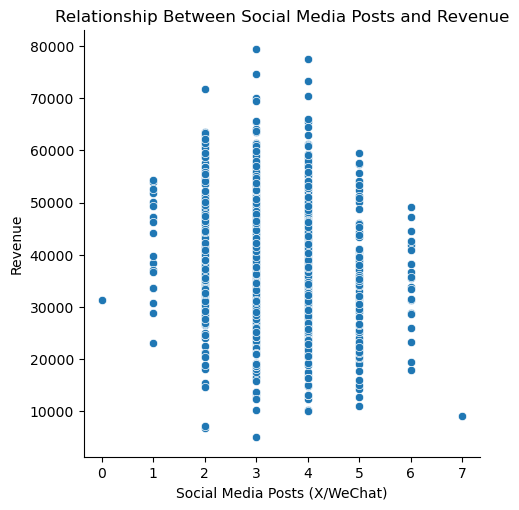

In [406]:
social_media_scatter = sns.relplot(x='X/WeChat_Posts', y='Revenue', data=data)
plt.xlabel('Social Media Posts (X/WeChat)')
plt.title('Relationship Between Social Media Posts and Revenue')
plt.show()

In [649]:
m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Revenue   R-squared:                       0.820
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     488.1
Date:                Sun, 02 Mar 2025   Prob (F-statistic):          1.41e-235
Time:                        23:55:10   Log-Likelihood:                -6458.4
No. Observations:                 650   AIC:                         1.293e+04
Df Residuals:                     643   BIC:                         1.296e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -5.139e+04   2184.869    -23.519      0.000   -5.57e+04   -4.71e+04
X/WeChat_Posts     -2138.0492    195.660    -10.927      0.000   -2522.260   -1753.838
Local_TV_Spend         1.7691      0.051     34.853      0.000       1.669       1.869
Digital_Spend          3.2965      0.388      8.490      0.000       2.534       4.059
Instore_Spend          4.0027      0.200     19.990      0.000       3.609       4.396
Employees_Involved  2093.8030     63.575     32.935      0.000    1968.964    2218.642
Event_Type          -220.0820    255.834     -0.860      0.390    -722.452     282.288
==============================================================================
Omnibus:                        0.209   Durbin-Watson:                   2.041
Prob(Omnibus):                  0.901   Jarque-Bera (JB):                0.149
Skew:                           0.035   Prob(JB):                        0.928
Kurtosis:                       3.026   Cond. No.                     3.53e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.53e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

__Managerial Insight__ <br>
P&G should examine its social media marketing strategy. It should conduct sentiment analysis on social media posts related to its posts to determine what its target audience is saying. It should also conduct A/B tests to identify the marketing message that will drive revenue. These suggestions can improve P&G's ROI on social media. 


__Finding 2__ <br>
Events are not driving revenue.

__Evidence__ <br>
The first bar graph (below) shows a relatively small negative impact on revenue (while it looks larger than the spending for TV, digital, and instore, the units are much smaller). The model summary (above) shows that events overall have little effect on revenue, which can be seen through its negative t-value. Digging deeper, the second bar graph (below), further demonstrates that none of the event subcategories have an impact on revenue. 


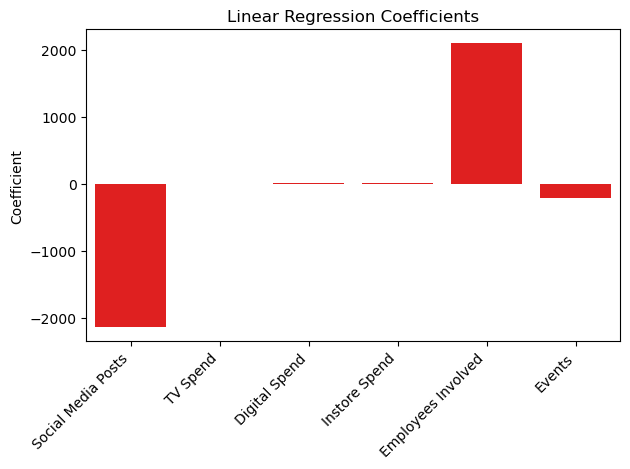

In [631]:
LR_Coefficient_Bar = sns.barplot(x=keys, y='Coefficient', data=coefficient_df, color='red', linewidth=1.5)
plt.title('Linear Regression Coefficients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

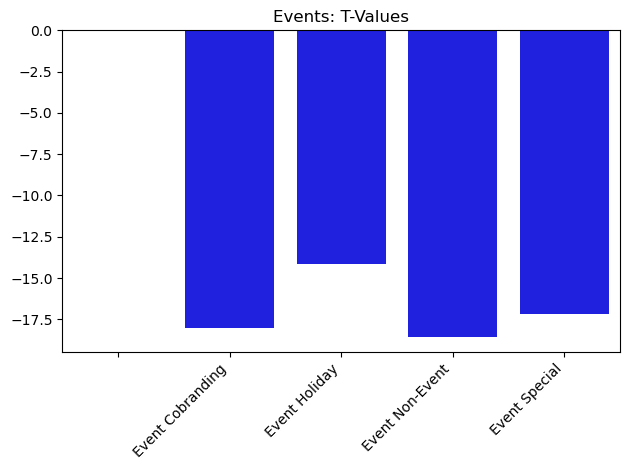

In [643]:
#graph for event t-values
Events_Tvalue = sns.barplot(x=keys, y='T-Values', data=E4_df, color='blue', linewidth=1.5)
plt.title('Events: T-Values')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

__Managerial Insight__ <br>
P&G should pause investing in events as they do not increase revenue. It should re-evaluate its event strategy to identify where the issues are, so that events can become revenue drivers.

__Finding 3__ <br>
Instore, digital, and TV spend produce are major drivers of revenue. 


__Evidence__ <br>
The chart shown below shows the expected increase in revenue for a one unit increase of the marketing channels (the first column). As already shown, you can ignore social media and events. Even though increasing the number of employees involved looks like it would increase revenue, increases to this would be small, which would limit its effect on revenue. Therefore, P&G should focus on digital, TV, and instore spend. The line graph below shows the expected ROI based on spend.

In [679]:
#create dataframe for graph showing coefficients for the independent variables
coefficient_dict = {'X/Wechat_Posts': -2167.5312, 'Local_TV_Spend': 1.6607, 'Digital_Spend': 3.3061, 'Instore_Spend': 4.0743, 'Employees_Involved': 2064.0695, 'Event_Type': -220.0820}
keyscoefficient = np.array(list(coefficient_dict.keys()))
valuescoefficient = np.array(list(coefficient_dict.values()))
coefficient_df = pd.DataFrame(valuescoefficient, index=keyscoefficient, columns=['Coefficient'])
coefficient_df

,Coefficient
X/Wechat_Posts,-2167.5312
Local_TV_Spend,1.6607
Digital_Spend,3.3061
Instore_Spend,4.0743
Employees_Involved,2064.0695
Event_Type,-220.0820


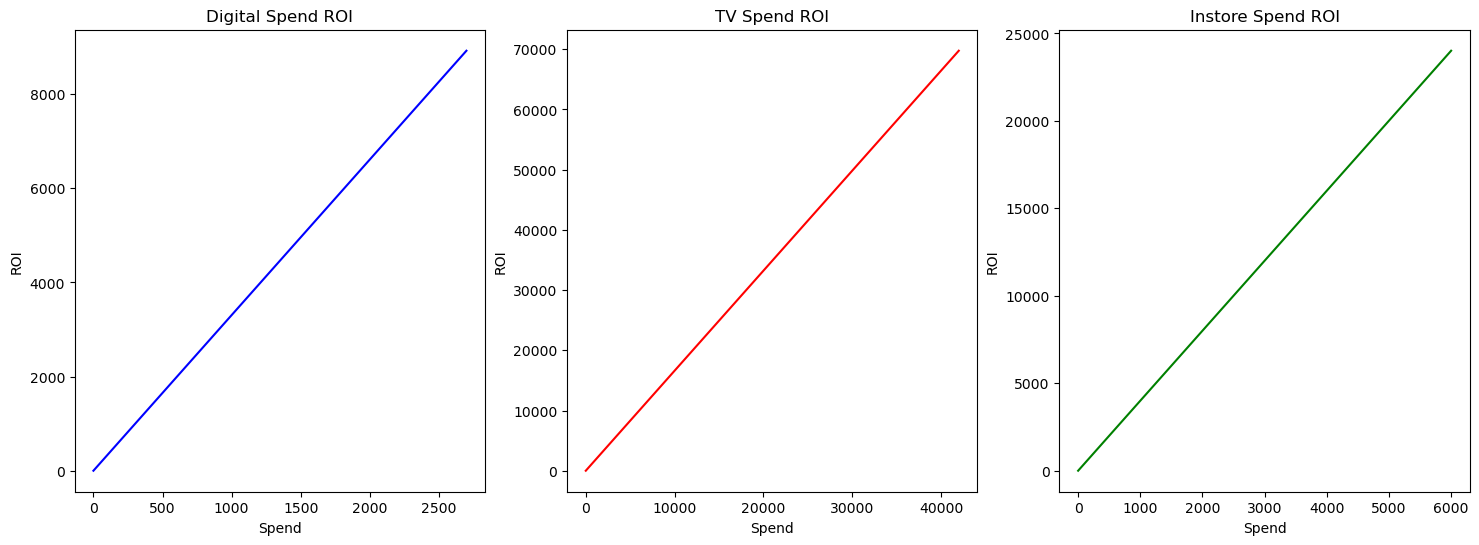

In [908]:
#create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
#plot for digital ROI
digital_range = np.arange(0, 2700)
digital_coefficient = 3.3061
digital_ROI = digital_range * digital_coefficient
sns.lineplot(x=digital_range, y=digital_ROI, ax=axes[0], color='blue')
axes[0].set_title('Digital Spend ROI')
axes[0].set_xlabel('Spend')
axes[0].set_ylabel('ROI')

#plot for TV ROI
TV_range = np.arange(0, 42000)
TV_coefficient = 1.6607
TV_ROI = TV_range * TV_coefficient
sns.lineplot(x=TV_range, y=TV_ROI, ax=axes[1], color='red')
axes[1].set_title('TV Spend ROI')
axes[1].set_xlabel('Spend')
axes[1].set_ylabel('ROI')

#plot for Instore ROI
Instore_range = np.arange(0, 6000)
Instore_coefficient = 4.0027
Instore_ROI = Instore_range * Instore_coefficient
sns.lineplot(x=Instore_range, y=Instore_ROI, ax=axes[2], color='green')
axes[2].set_title('Instore Spend ROI')
axes[2].set_xlabel('Spend')
axes[2].set_ylabel('ROI')
plt.show()

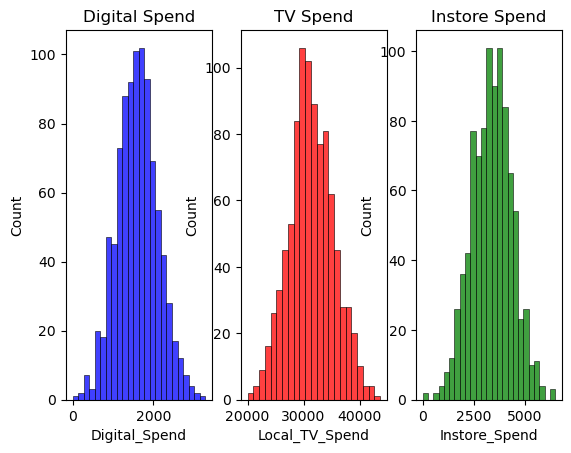

In [832]:
#create histograms for tv, instore, and digital spend
fig, axes = plt.subplots(1, 3)
sns.histplot(data['Digital_Spend'], ax=axes[0], color='blue')
axes[0].set_title('Digital Spend')

sns.histplot(data['Local_TV_Spend'], ax=axes[1], color='red')
axes[1].set_title('TV Spend')

sns.histplot(data['Instore_Spend'], ax=axes[2], color='green')
axes[2].set_title('Instore Spend')
plt.show()

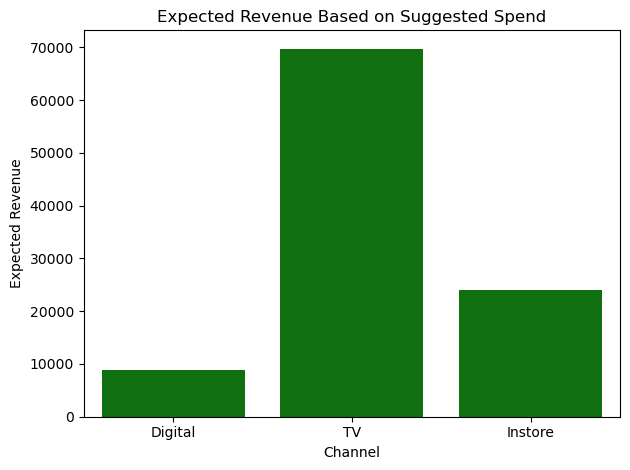

In [891]:
Expected_Revenue = [8926.47, 69749.4, 24016.2]
Expected_Revenue_df = pd.DataFrame(Expected_Revenue, columns=['Expected Revenue'])
Expected_Revenue_df['Channel'] = ['Digital', 'TV', 'Instore']
sns.barplot(x='Channel', y='Expected Revenue', data=Expected_Revenue_df, color='green')
plt.title('Expected Revenue Based on Suggested Spend')
plt.xlabel('Channel')
plt.ylabel('Expected Revenue')
plt.tight_layout()
plt.show()



__Managerial Insight__ <br>
The data suggests that for every dollar spent on digital, TV, and instore marketing, P&G will see an ROI of 3.3061, 1.6607, and 4.0027, respectively. As the data for each of the three marketing channels only goes up to approximately 2,700 for digital, 42,000 for TV, and 6,000 for instore, we cannot accurately predict revenue past these points (however, they may have the potential to return an ROI beyond these amounts, which should be explored). Based on the distribution of spending for these three marketing channels, P&G is currently underspending and can safely increase digital spending to 2700 (digital), 42,000 (TV), and 6,000 (instore) per store, which will create revenue per store (as seen in the chart above) of 8926.47 (digital), 69749.4 (TV), and 24016.2 (instore).

In [ ]:
#data prep/cleaning
#import necessary tools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#import dataset
data = pd.read_csv('P&G Marketing Data.csv')
#check for missing data
data.isnull().any()
data.isnull().sum()
#56 rows are missing data for TV ad spend, which is significant
#delete rows with missing data
data = data.dropna(axis=0)
data.isnull().any()
#rows with missing data have been dropped
#check types of data in the dataframe
data.info()
#identify event categories
categories = data['event'].unique()
categories
# there are objects in the event column; these will have to be changed into numerical values

def event2num(event_string):
    if event_string == 'non-event':
        return 0
    elif event_string == 'special':
        return 1
    elif event_string == 'cobranding':
        return 2
    else:
        return 3
data['event_num'] = data['event'].apply(event2num)
data.head()
#delete event column and change event_num to event
data.drop(['event'], axis=1, inplace=True)
data.head()
#change event_num to event
data.rename(columns={'event_num':'event'}, inplace=True)
data.head()
#check/change column names to improve clarity
data.columns = ['Store_Num', 'Revenue', 'X/WeChat_Posts', 'Local_TV_Spend', 'Digital_Spend', 'Instore_Spend', 'Employees_Involved', 'Event_Type']
data.head()
#import linear regression 
from sklearn.linear_model import LinearRegression
model = LinearRegression()
#set independent variables as X
#exclude Store_Num from model
X = data.iloc[:, [2,3,4,5,6,7]]
X.head()
#set dependent variable (Revenue) as y
y = data.iloc[:, 1]
y.head()
#import train test split
from sklearn.model_selection import train_test_split
#set training to 70% and testing to 30%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
#fit the model
model.fit(X_train, y_train)
#no need to drop columns (ie: data.drop['Employees'], axis=1, inplace=True) for now. After running the regression, I may need to drop one or more to reduce collinearity
#use seaborn to get an idea of the linear regression model
import seaborn as sns
%matplotlib inline
sns.pairplot(data, x_vars=['X/WeChat_Posts', 'Local_TV_Spend', 'Digital_Spend', 'Instore_Spend', 'Employees_Involved', 'Event_Type'], y_vars='Revenue')
plt.show()
#coefficients
model.coef_
#intercept
model.intercept_
model.predict(X_test)
y_pred = model.predict(X_test)
y_pred
#import metrics to test accuracy
from sklearn import metrics
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y_test, y_pred))
import statsmodels.api as sm
X_intercept = sm.add_constant(X_train)
m = sm.OLS(y_train, X_intercept).fit()
m.summary()
#feature selection for model optimization
model2 = LinearRegression()
X2 = data.iloc[:, [2,3,6,7]]
X2.head()
y2 = data.iloc[:, 1]
y2.head()
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, random_state=1)
model2.fit(X2_train, y2_train)
model2.coef_
model2.intercept_
model2.predict(X2_test)
y2_pred = model2.predict(X2_test)
y2_pred
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y2_test, y2_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y2_test, y2_pred))
import statsmodels.api as sm
X2_intercept = sm.add_constant(X2_train)
m2 = sm.OLS(y2_train, X2_intercept).fit()
m2.summary()
#Removing digital and instore spend reduced the model's fit
#Test removing event type 
from sklearn.linear_model import LinearRegression
model3 = LinearRegression()
#exclude Event from model
X3 = data.iloc[:, [2,3,4,5,6]]
#set dependent variable (Revenue) as y
y3 = data.iloc[:, 1]
from sklearn.model_selection import train_test_split
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, random_state=1)
model3.fit(X3_train, y3_train)
model3.coef_
model3.intercept_
model3.predict(X3_test)
y3_pred = model3.predict(X3_test)
y3_pred
from sklearn import metrics
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y3_test, y3_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y3_test, y3_pred))
import statsmodels.api as sm
X3_intercept = sm.add_constant(X3_train)
m3 = sm.OLS(y3_train, X3_intercept).fit()
m3.summary()
#removing event decrease the root of mean squared error by approximately 5%, but decreased R2 by 0.01. The new model is better at minimizing errors, but explains variation in the target variable slightly worse.
#create dataframe for graph showing coefficient values
coefficient_dict = {'Social Media Posts': -11.207, 'TV Spend': 35.449, 'Digital Spend': 9.09, 'Instore Spend': 20.491, 'Employees Involved': 31.409, 'Events': 0.277}
keys = np.array(list(coefficient_dict.keys()))
values = np.array(list(coefficient_dict.values()))
coefficient_df = pd.DataFrame(values, index=keys, columns=['Coefficient'])
coefficient_df
social_media_scatter = sns.relplot(x='X/WeChat_Posts', y='Revenue', data=data)
plt.xlabel('Social Media Posts (X/WeChat)')
plt.title('Relationship Between Social Media Posts and Revenue')
plt.show()
LR_Coefficient_Bar = sns.barplot(x=keys, y='Coefficient', data=coefficient_df, color='red', linewidth=1.5)
plt.title('Linear Regression Coefficients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
LR_Coefficient_Bar = sns.barplot(x=keys, y='Coefficient', data=coefficient_df, color='red', linewidth=1.5)
plt.title('Linear Regression Coefficients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [459]:
#create a dataframe to analyze the effects of the different kinds of events on revenue
events_df = pd.read_csv('P&G Marketing Data.csv')
events_df = pd.get_dummies(events_df, columns=['event'])
events_df.head()

,Unnamed: 0,revenue,reach,local_tv,online,instore,person,event_cobranding,event_holiday,event_non_event,event_special
0,845,45860.28,2,31694.91,2115,3296,8,False,False,True,False
1,483,63588.23,2,35040.17,1826,2501,14,False,False,False,True
2,513,23272.69,4,30992.82,1851,2524,6,False,False,False,True
3,599,45911.23,2,29417.78,2437,3049,12,False,False,False,True
4,120,36644.23,2,35611.11,1122,1142,13,True,False,False,False


In [521]:
#turn true and false to 1 and 0
def  cobranding2number(event_cobranding_string):
    if event_cobranding_string == True:
        return 1
    else:
        return 0

def  event_holiday2number(event_holiday_string):
    if event_holiday_string == True:
        return 1
    else:
        return 0

def  event_non_event2number(event_non_event_string):
    if event_non_event_string == True:
        return 1
    else:
        return 0

def  event_special2number(event_special_string):
    if event_special_string == True:
        return 1
    else:
        return 0

events_df['event_cobranding_num'] = events_df['event_cobranding'].apply(cobranding2number)
events_df['event_holiday_num'] = events_df['event_holiday'].apply(event_holiday2number)
events_df['event_non_event_num'] = events_df['event_non_event'].apply(event_non_event2number)
events_df['event_special_num'] = events_df['event_special'].apply(event_special2number)
events_df.head()

,Unnamed: 0,revenue,reach,local_tv,online,instore,person,event_cobranding,event_holiday,event_non_event,event_special,event_cobranding_num,event_holiday_num,event_non_event_num,event_special_num
0,845,45860.28,2,31694.91,2115,3296,8,False,False,True,False,0,0,1,0
1,483,63588.23,2,35040.17,1826,2501,14,False,False,False,True,0,0,0,1
2,513,23272.69,4,30992.82,1851,2524,6,False,False,False,True,0,0,0,1
3,599,45911.23,2,29417.78,2437,3049,12,False,False,False,True,0,0,0,1
4,120,36644.23,2,35611.11,1122,1142,13,True,False,False,False,1,0,0,0


In [523]:
#delete columns
events_df.drop(['Unnamed: 0', 'event_cobranding', 'event_holiday', 'event_non_event', 'event_special'], axis=1, inplace=True)
events_df.head()

,revenue,reach,local_tv,online,instore,person,event_cobranding_num,event_holiday_num,event_non_event_num,event_special_num
0,45860.28,2,31694.91,2115,3296,8,0,0,1,0
1,63588.23,2,35040.17,1826,2501,14,0,0,0,1
2,23272.69,4,30992.82,1851,2524,6,0,0,0,1
3,45911.23,2,29417.78,2437,3049,12,0,0,0,1
4,36644.23,2,35611.11,1122,1142,13,1,0,0,0


In [527]:
#check/change column names to improve clarity
events_df.columns = ['Revenue', 'X/WeChat_Posts', 'Local_TV_Spend', 'Digital_Spend', 'Instore_Spend', 'Employees_Involved', 'Event_Cobranding', 'Event_Holiday', 'Event_Non_Event', 'Event_Special']
events_df.head()

,Revenue,X/WeChat_Posts,Local_TV_Spend,Digital_Spend,Instore_Spend,Employees_Involved,Event_Cobranding,Event_Holiday,Event_Non_Event,Event_Special
0,45860.28,2,31694.91,2115,3296,8,0,0,1,0
1,63588.23,2,35040.17,1826,2501,14,0,0,0,1
2,23272.69,4,30992.82,1851,2524,6,0,0,0,1
3,45911.23,2,29417.78,2437,3049,12,0,0,0,1
4,36644.23,2,35611.11,1122,1142,13,1,0,0,0


In [601]:
#create model
#import linear regression 
from sklearn.linear_model import LinearRegression
model_4events = LinearRegression()
#set independent variables as X
X4E = events_df.iloc[:, 1:10]
X4E = X4E.dropna()
y4E = events_df.iloc[:, 0]
y4E = y4E[X4E.index]
#import train test split
from sklearn.model_selection import train_test_split
#set training to 70% and testing to 30%
X4E_train, X4E_test, y4E_train, y4E_test = train_test_split(X4E, y4E, test_size=0.3)
#fit the model
model_4events.fit(X4E_train, y4E_train)

LinearRegression()

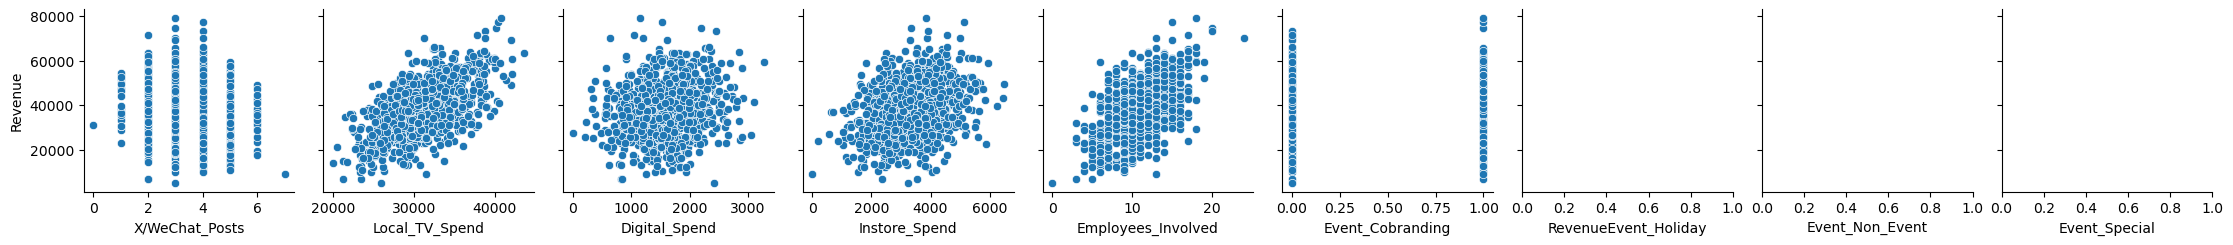

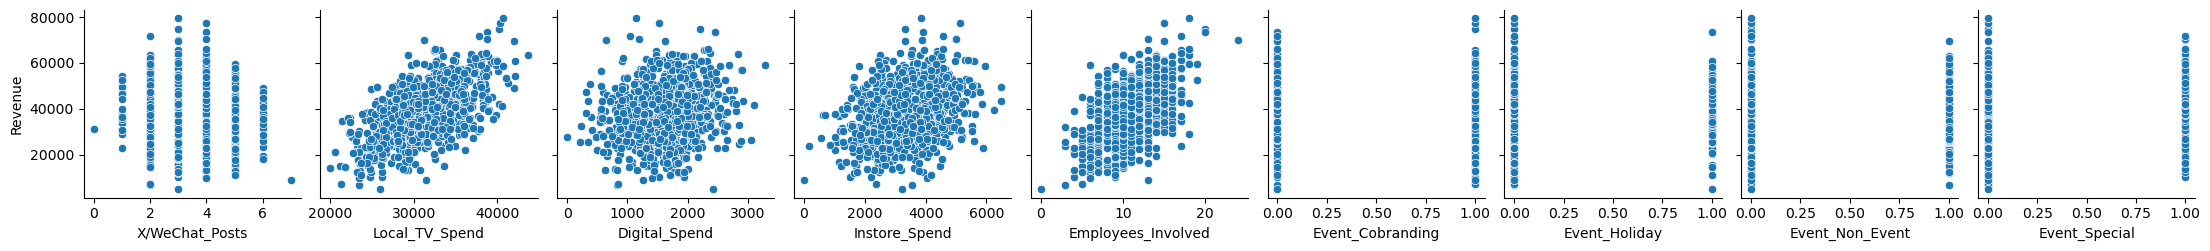

In [615]:
import seaborn as sns
%matplotlib inline
sns.pairplot(events_df, x_vars=['X/WeChat_Posts', 'Local_TV_Spend', 'Digital_Spend', 'Instore_Spend', 'Employees_Involved', 'Event_Cobranding', 'Event_Holiday', 'Event_Non_Event', 'Event_Special'], y_vars='Revenue')
plt.show()

In [619]:
#coefficients
model_4events.coef_
#intercept
model_4events.intercept_

-47978.244644049344

In [621]:
model_4events.predict(X4E_test)
y4E_pred = model_4events.predict(X4E_test)
y4E_pred
#import metrics to test accuracy
from sklearn import metrics
print("root of mean squared error: ", np.sqrt(metrics.mean_squared_error(y4E_test, y4E_pred)))
print("mean absolute error: ", metrics.mean_squared_error(y4E_test, y4E_pred))
import statsmodels.api as sm
X4E_intercept = sm.add_constant(X4E_train)
m4E = sm.OLS(y4E_train, X4E_intercept).fit()
m4E.summary()

root of mean squared error:  5044.706267834278
mean absolute error:  25449061.32872645


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Revenue   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     342.6
Date:                Sun, 02 Mar 2025   Prob (F-statistic):          9.88e-226
Time:                        23:06:59   Log-Likelihood:                -6463.2
No. Observations:                 650   AIC:                         1.294e+04
Df Residuals:                     641   BIC:                         1.298e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -3.838e+04   1651.647    -23.239      0.000   -4.16e+04   -3.51e+04
X/WeChat_Posts     -2167.5312    199.379    -10.871      0.000   -2559.047   -1776.016
Local_TV_Spend         1.6607      0.050     33.475      0.000       1.563       1.758
Digital_Spend          3.3061      0.400      8.258      0.000       2.520       4.092
Instore_Spend          4.0743      0.204     19.997      0.000       3.674       4.474
Employees_Involved  2064.0695     65.557     31.485      0.000    1935.338    2192.801
Event_Cobranding   -9183.8769    510.106    -18.004      0.000   -1.02e+04   -8182.197
Event_Holiday      -9311.3760    658.973    -14.130      0.000   -1.06e+04   -8017.369
Event_Non_Event    -1.037e+04    558.647    -18.559      0.000   -1.15e+04   -9270.745
Event_Special      -9519.5991    554.580    -17.165      0.000   -1.06e+04   -8430.585
==============================================================================
Omnibus:                        0.337   Durbin-Watson:                   2.047
Prob(Omnibus):                  0.845   Jarque-Bera (JB):                0.380
Skew:                           0.054   Prob(JB):                        0.827
Kurtosis:                       2.951   Cond. No.                     7.56e+19
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.14e-28. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

In [629]:
#create dataframe for graph showing t-values for the types of events
tvalue_dict = {'Event Cobranding': -18.004, 'Event Holiday': -14.13, 'Event Non-Event': -18.559, 'Event Special': -17.165}
keys4E = np.array(list(tvalue_dict.keys()))
values4E = np.array(list(tvalue_dict.values()))
E4_df = pd.DataFrame(values4E, index=keys4E, columns=['T-Value'])
E4_df

,T-Value
Event Cobranding,-18.004
Event Holiday,-14.130
Event Non-Event,-18.559
Event Special,-17.165
